# EN3160 Assignment 3 — Neural Networks

**Name:** D. P. Heshan Ranasinghe  
**Index:** 230521E  
**GitHub profile:** [DPHeshanRanasinghe](https://github.com/DPHeshanRanasinghe)


## Setup

The experiments use PyTorch, torchvision, NumPy, pandas and matplotlib. Computation runs on a CUDA GPU when available; otherwise, it uses the CPU. Accuracies are displayed as percentages in the result tables.

In [25]:
import os

# Configure deterministic CUDA operations before importing PyTorch.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import copy
import json
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from IPython.display import display, HTML

SEED = 230521
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = Path("data")
RESULT_DIR = Path("results")

Q1_EPOCHS = 10
Q2_EPOCHS = 10
Q3_EPOCHS = 25

NUM_WORKERS = 0


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def make_loader(dataset, batch_size, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        generator=generator,
        pin_memory=(DEVICE.type == "cuda"),
    )


seed_everything()

print(f"Device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")

Device: cuda
PyTorch version: 2.5.1


In [26]:
display(HTML("""
<style>
@page {
    size: A4 portrait;
    margin: 12mm;
}

@media print {
    body,
    .jp-RenderedHTMLCommon,
    .text_cell_render {
        font-family: Arial, sans-serif;
        font-size: 9pt;
        line-height: 1.15;
        color: #111;
    }

    .jp-Notebook {
        padding: 0 !important;
        margin: 0 !important;
        max-width: none !important;
    }

    .jp-Cell {
        margin-bottom: 4pt !important;
    }

    pre,
    code {
        font-family: Consolas, "DejaVu Sans Mono", monospace;
        font-size: 7pt;
    }

    pre {
        white-space: pre-wrap !important;
        overflow-wrap: anywhere;
    }

    .jp-InputPrompt,
    .jp-OutputPrompt,
    .prompt,
    .anchor-link {
        display: none !important;
    }

    h1, h2, h3 {
        break-after: avoid;
        page-break-after: avoid;
    }

    table {
        border-collapse: collapse;
        font-size: 8pt;
        break-inside: avoid;
    }

    th, td {
        padding: 3pt 5pt;
    }

    .jp-RenderedImage,
    .output_png {
        break-inside: avoid;
    }

    img {
        max-width: 100% !important;
        height: auto;
    }
}
</style>
"""))

In [27]:
def plot_histories(histories, heldout="test"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

    for name, history in histories.items():
        frame = pd.DataFrame(history)

        for split, style in [("train", "-"), (heldout, "--")]:
            label = f"{name}: {split}"

            axes[0].plot(
                frame["epoch"],
                frame[f"{split}_loss"],
                linestyle=style,
                label=label,
            )

            axes[1].plot(
                frame["epoch"],
                100 * frame[f"{split}_acc"],
                linestyle=style,
                label=label,
            )

    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)")

    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    fig.tight_layout()
    plt.show()


def result_table(names, results, heldout="test"):
    rows = []

    for name in names:
        metrics = results[name]

        rows.append({
            "Model / method": name,
            "Training loss": metrics["train_loss"],
            "Training accuracy (%)": 100 * metrics["train_acc"],
            f"{heldout.title()} loss": metrics[f"{heldout}_loss"],
            f"{heldout.title()} accuracy (%)":
                100 * metrics[f"{heldout}_acc"],
        })

    table = pd.DataFrame(rows)

    display(
        table.style
        .format({
            "Training loss": "{:.4f}",
            "Training accuracy (%)": "{:.2f}",
            f"{heldout.title()} loss": "{:.4f}",
            f"{heldout.title()} accuracy (%)": "{:.2f}",
        })
        .hide(axis="index")
    )


def save_run(name, history, metrics, state):
    RESULT_DIR.mkdir(parents=True, exist_ok=True)

    pd.DataFrame(history).to_csv(
        RESULT_DIR / f"{name}_history.csv",
        index=False,
    )

    metadata = {
        **metrics,
        "seed": SEED,
        "device": str(DEVICE),
        "torch_version": str(torch.__version__),
    }

    with open(
        RESULT_DIR / f"{name}_metrics.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(metadata, file, indent=2)

    torch.save(state, RESULT_DIR / f"{name}.pt")

## Q1 — Manual CIFAR-10 dense network

The network takes a flattened CIFAR-10 image with 3072 values, passes it through 100 sigmoid hidden units, and produces 10 output logits. Images are normalised to [-1, 1]. The forward pass, cross-entropy loss, gradients and parameter updates are implemented manually without automatic differentiation.

Training uses Xavier initialisation, a batch size of 50, and 10 epochs. The learning rate is multiplied by 0.9 after each epoch.

### Learning-rate selection

Initial learning rates of 0.03, 0.1 and 0.3 were compared using a fixed split of 45,000 training images and 5,000 validation images. Each experiment used the same initial weights and data order.

A learning rate of **0.3** achieved the highest final validation accuracy (**47.62%**) and lowest validation loss (**1.5048**). This setting was selected for the final model, which was trained from scratch on all 50,000 training images for 10 epochs.

In [28]:
from torch.utils.data import random_split

Q1_BATCH_SIZE = 50
Q1_LR_CANDIDATES = [0.03, 0.1, 0.3]
Q1_LR_DECAY = 0.9

cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5),
    ),
])


def cifar_loaders():
    train_dataset = datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=cifar_transform,
    )

    test_dataset = datasets.CIFAR10(
        root=DATA_DIR,
        train=False,
        download=False,
        transform=cifar_transform,
    )

    return {
        "train": make_loader(
            train_dataset, Q1_BATCH_SIZE, shuffle=True
        ),
        "train_eval": make_loader(
            train_dataset, Q1_BATCH_SIZE, shuffle=False
        ),
        "test": make_loader(
            test_dataset, Q1_BATCH_SIZE, shuffle=False
        ),
    }

In [29]:
def q1_init(
    input_dim=3072,
    hidden_dim=100,
    classes=10,
    device=DEVICE,
    dtype=torch.float32,
):
    W1 = torch.randn(
        input_dim, hidden_dim, device=device, dtype=dtype
    ) * (2.0 / (input_dim + hidden_dim)) ** 0.5

    W2 = torch.randn(
        hidden_dim, classes, device=device, dtype=dtype
    ) * (2.0 / (hidden_dim + classes)) ** 0.5

    return {
        "W1": W1,
        "b1": torch.zeros(hidden_dim, device=device, dtype=dtype),
        "W2": W2,
        "b2": torch.zeros(classes, device=device, dtype=dtype),
    }


@torch.no_grad()
def q1_forward(images, params):
    x = images.flatten(start_dim=1)
    h = torch.sigmoid(x @ params["W1"] + params["b1"])
    scores = h @ params["W2"] + params["b2"]
    return x, h, scores


@torch.no_grad()
def q1_cross_entropy(scores, labels):
    shifted = scores - scores.max(dim=1, keepdim=True).values
    log_probs = shifted - torch.log(
        shifted.exp().sum(dim=1, keepdim=True)
    )

    rows = torch.arange(labels.size(0), device=scores.device)
    loss = -log_probs[rows, labels].mean()

    dscores = log_probs.exp()
    dscores[rows, labels] -= 1
    dscores /= labels.size(0)

    return loss, dscores


@torch.no_grad()
def q1_gradients(x, h, dscores, params):
    dW2 = h.T @ dscores
    db2 = dscores.sum(dim=0)

    dh = dscores @ params["W2"].T
    dz1 = dh * h * (1 - h)

    return {
        "W1": x.T @ dz1,
        "b1": dz1.sum(dim=0),
        "W2": dW2,
        "b2": db2,
    }


@torch.no_grad()
def q1_update(params, gradients, lr):
    for name in params:
        params[name] -= lr * gradients[name]


@torch.no_grad()
def q1_correct_count(scores, labels):
    return (scores.argmax(dim=1) == labels).sum().item()


@torch.no_grad()
def q1_evaluate(params, loader):
    loss_sum = 0.0
    correct = 0
    count = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        _, _, scores = q1_forward(images, params)
        loss, _ = q1_cross_entropy(scores, labels)

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        correct += q1_correct_count(scores, labels)
        count += batch_size

    return {
        "loss": loss_sum / count,
        "acc": correct / count,
    }

In [30]:
@torch.no_grad()
def q1_train(params, loaders, initial_lr, heldout="test"):
    history = []
    lr = initial_lr

    for epoch in range(1, Q1_EPOCHS + 1):
        for images, labels in loaders["train"]:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            x, h, scores = q1_forward(images, params)
            _, dscores = q1_cross_entropy(scores, labels)
            gradients = q1_gradients(x, h, dscores, params)
            q1_update(params, gradients, lr)

        train_metrics = q1_evaluate(
            params, loaders["train_eval"]
        )
        heldout_metrics = q1_evaluate(
            params, loaders[heldout]
        )

        history.append({
            "epoch": epoch,
            "lr": lr,
            "train_loss": train_metrics["loss"],
            "train_acc": train_metrics["acc"],
            f"{heldout}_loss": heldout_metrics["loss"],
            f"{heldout}_acc": heldout_metrics["acc"],
        })

        print(
            f"Epoch {epoch:02d}/{Q1_EPOCHS} | "
            f"Train loss: {train_metrics['loss']:.4f}, "
            f"accuracy: {train_metrics['acc']:.2%} | "
            f"{heldout.title()} loss: "
            f"{heldout_metrics['loss']:.4f}, "
            f"accuracy: {heldout_metrics['acc']:.2%}"
        )

        lr *= Q1_LR_DECAY

    return history


Initial learning rate: 0.03
Epoch 01/10 | Train loss: 1.7756, accuracy: 39.13% | Val loss: 1.7840, accuracy: 37.70%
Epoch 02/10 | Train loss: 1.7192, accuracy: 40.78% | Val loss: 1.7437, accuracy: 38.48%
Epoch 03/10 | Train loss: 1.6876, accuracy: 41.62% | Val loss: 1.7213, accuracy: 39.66%
Epoch 04/10 | Train loss: 1.6614, accuracy: 42.84% | Val loss: 1.7043, accuracy: 40.22%
Epoch 05/10 | Train loss: 1.6398, accuracy: 43.42% | Val loss: 1.6903, accuracy: 41.06%
Epoch 06/10 | Train loss: 1.6244, accuracy: 44.26% | Val loss: 1.6795, accuracy: 42.00%
Epoch 07/10 | Train loss: 1.6127, accuracy: 44.72% | Val loss: 1.6727, accuracy: 41.66%
Epoch 08/10 | Train loss: 1.5990, accuracy: 45.11% | Val loss: 1.6625, accuracy: 42.64%
Epoch 09/10 | Train loss: 1.5900, accuracy: 45.78% | Val loss: 1.6582, accuracy: 42.80%
Epoch 10/10 | Train loss: 1.5815, accuracy: 45.87% | Val loss: 1.6501, accuracy: 42.74%

Initial learning rate: 0.1
Epoch 01/10 | Train loss: 1.6938, accuracy: 41.61% | Val loss: 

,Initial learning rate,Training accuracy (%),Validation accuracy (%),Validation loss
0,0.30,61.2311,47.62,1.5048
1,0.10,53.4200,46.34,1.5482
2,0.03,45.8689,42.74,1.6501


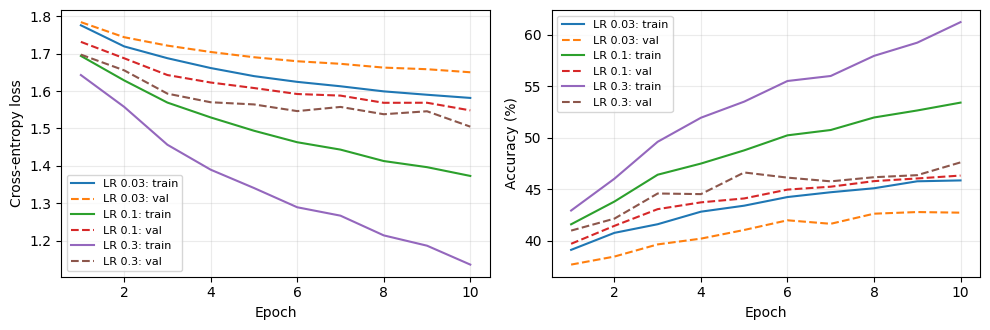

Selected initial learning rate: 0.3


In [31]:
from torch.utils.data import random_split

Q1_VAL_SIZE = 5000

q1_tuning_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=cifar_transform,
)

q1_train_subset, q1_val_subset = random_split(
    q1_tuning_dataset,
    [
        len(q1_tuning_dataset) - Q1_VAL_SIZE,
        Q1_VAL_SIZE,
    ],
    generator=torch.Generator().manual_seed(SEED),
)


def q1_validation_loaders():
    return {
        "train": make_loader(
            q1_train_subset, Q1_BATCH_SIZE, shuffle=True
        ),
        "train_eval": make_loader(
            q1_train_subset, Q1_BATCH_SIZE, shuffle=False
        ),
        "val": make_loader(
            q1_val_subset, Q1_BATCH_SIZE, shuffle=False
        ),
    }


q1_tuning_histories = {}
q1_tuning_rows = []

for candidate_lr in Q1_LR_CANDIDATES:
    print(f"\nInitial learning rate: {candidate_lr}")

    seed_everything()
    tuning_loaders = q1_validation_loaders()
    tuning_params = q1_init()

    tuning_history = q1_train(
        tuning_params,
        tuning_loaders,
        initial_lr=candidate_lr,
        heldout="val",
    )

    name = f"LR {candidate_lr}"
    q1_tuning_histories[name] = tuning_history
    final = tuning_history[-1]

    q1_tuning_rows.append({
        "Initial learning rate": candidate_lr,
        "Training accuracy (%)": 100 * final["train_acc"],
        "Validation accuracy (%)": 100 * final["val_acc"],
        "Validation loss": final["val_loss"],
    })

q1_tuning_table = (
    pd.DataFrame(q1_tuning_rows)
    .sort_values(
        ["Validation accuracy (%)", "Validation loss"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

Q1_SELECTED_LR = float(
    q1_tuning_table.loc[0, "Initial learning rate"]
)

# Save results before displaying the plots.
RESULT_DIR.mkdir(parents=True, exist_ok=True)

q1_tuning_table.to_csv(
    RESULT_DIR / "q1_learning_rate_comparison.csv",
    index=False,
)

pd.concat(
    [
        pd.DataFrame(history).assign(candidate=name)
        for name, history in q1_tuning_histories.items()
    ],
    ignore_index=True,
).to_csv(
    RESULT_DIR / "q1_learning_rate_histories.csv",
    index=False,
)

display(q1_tuning_table.round(4))
plot_histories(q1_tuning_histories, heldout="val")

print(f"Selected initial learning rate: {Q1_SELECTED_LR}")

Final training on all 50,000 training images
Initial learning rate: 0.3
Epoch 01/10 | Train loss: 1.6737, accuracy: 40.84% | Test loss: 1.7091, accuracy: 39.15%
Epoch 02/10 | Train loss: 1.5272, accuracy: 47.04% | Test loss: 1.5979, accuracy: 44.67%
Epoch 03/10 | Train loss: 1.4751, accuracy: 47.93% | Test loss: 1.5897, accuracy: 44.30%
Epoch 04/10 | Train loss: 1.4012, accuracy: 51.45% | Test loss: 1.5488, accuracy: 46.46%
Epoch 05/10 | Train loss: 1.3537, accuracy: 53.02% | Test loss: 1.5285, accuracy: 47.53%
Epoch 06/10 | Train loss: 1.2866, accuracy: 55.26% | Test loss: 1.5055, accuracy: 48.02%
Epoch 07/10 | Train loss: 1.2414, accuracy: 56.91% | Test loss: 1.5040, accuracy: 48.09%
Epoch 08/10 | Train loss: 1.1992, accuracy: 58.56% | Test loss: 1.4910, accuracy: 49.32%
Epoch 09/10 | Train loss: 1.1715, accuracy: 59.37% | Test loss: 1.4819, accuracy: 49.42%
Epoch 10/10 | Train loss: 1.1376, accuracy: 60.60% | Test loss: 1.4806, accuracy: 49.24%


Model / method,Training loss,Training accuracy (%),Test loss,Test accuracy (%)
Manual dense network,1.1376,60.60,1.4806,49.24


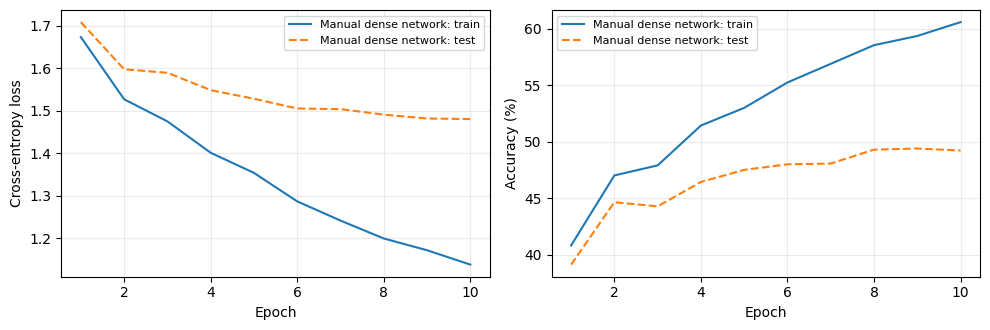

Training and evaluation time: 5.16 minutes


In [32]:
seed_everything()

q1_loaders = cifar_loaders()
q1_params = q1_init()

print(
    "Final training on all 50,000 training images\n"f"Initial learning rate: {Q1_SELECTED_LR}")

q1_start_time = time.perf_counter()

q1_history = q1_train(
    q1_params,
    q1_loaders,
    initial_lr=Q1_SELECTED_LR,
    heldout="test",
)

q1_elapsed = time.perf_counter() - q1_start_time

q1_results = {
    "Manual dense network": {
        key: q1_history[-1][key]
        for key in (
            "train_loss",
            "train_acc",
            "test_loss",
            "test_acc",
        )
    }
}

save_run(
    "q1_manual_tuned",
    q1_history,
    {
        **q1_results["Manual dense network"],
        "epochs": Q1_EPOCHS,
        "batch_size": Q1_BATCH_SIZE,
        "initial_lr": Q1_SELECTED_LR,
        "lr_decay": Q1_LR_DECAY,
        "selection_method": "Final-epoch validation accuracy",
        "validation_size": Q1_VAL_SIZE,
        "lr_candidates": Q1_LR_CANDIDATES,
        "elapsed_seconds": q1_elapsed,
    },
    q1_params,
)

result_table(["Manual dense network"], q1_results)
plot_histories({"Manual dense network": q1_history})

print(
    f"Training and evaluation time: "
    f"{q1_elapsed / 60:.2f} minutes"
)

### Results and discussion

After 10 epochs, the final network achieved a training accuracy of **60.60%** and a test accuracy of **49.24
%**, with cross-entropy losses of **1.1376** and **1.480**, respectively.

During learning-rate selection, increasing the initial learning rate improved both training and validation performance. However, the selected setting produced a training–validation accuracy gap of approximately 13.61 percentage points, suggesting overfitting.

The model has only one hidden layer and does not explicitly exploit local image structure through convolution. These architectural limitations may restrict its classification performance.

## Q2 — MNIST CNN comparison

Two convolutional networks are compared on MNIST. Images are padded from 28×28 to 32×32 and normalised using the same transformation for both models.

The LeNet-5 adaptation uses three 5×5 convolutions with 6, 16 and 120 output channels, tanh activations, average pooling, and fully connected layers with 84 and 10 units. It uses fully connected channel mappings and output logits rather than reproducing every detail of the original architecture.

The modern CNN uses three 3×3 convolutional layers with 32, 64 and 128 output channels. Each convolution is followed by batch normalisation and ReLU. Dropout provides regularisation.

Both models are trained for 10 epochs using Adam, a learning rate of 0.001, a batch size of 128, and cross-entropy loss. Each experiment starts with a fixed seed and a fresh data-loader generator.

Training and test metrics are measured in evaluation mode after each epoch. Results are reported for the final epoch, without selecting checkpoints using test accuracy. A test-set confusion matrix is also shown for each model.

In [38]:
Q2_BATCH_SIZE = 128
Q2_LR = 0.001

mnist_transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])


def mnist_loaders():
    train_dataset = datasets.MNIST(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=mnist_transform,
    )

    test_dataset = datasets.MNIST(
        root=DATA_DIR,
        train=False,
        download=False,
        transform=mnist_transform,
    )

    return {
        "train": make_loader(
            train_dataset, Q2_BATCH_SIZE, shuffle=True
        ),
        "train_eval": make_loader(
            train_dataset, Q2_BATCH_SIZE, shuffle=False
        ),
        "test": make_loader(
            test_dataset, Q2_BATCH_SIZE, shuffle=False
        ),
    }


class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.conv3 = nn.Conv2d(16, 120, kernel_size=5)

        self.pool = nn.AvgPool2d(kernel_size=2)

        self.fc1 = nn.Linear(120, 84)
        self.fc2 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(torch.tanh(self.conv1(x)))
        x = self.pool(torch.tanh(self.conv2(x)))
        x = torch.tanh(self.conv3(x))
        x = x.flatten(start_dim=1)
        x = torch.tanh(self.fc1(x))

        return self.fc2(x)


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(0.20),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128 * 4 * 4, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Check model output shapes without downloading data or training.
seed_everything()

q2_model_summary = []

for name, constructor in [
    ("LeNet-5", LeNet5),
    ("Small CNN", SmallCNN),
]:
    check_model = constructor().eval()

    with torch.no_grad():
        check_output = check_model(torch.zeros(2, 1, 32, 32))

    assert check_output.shape == (2, 10)

    conv_count = sum(
        isinstance(layer, nn.Conv2d)
        for layer in check_model.modules()
    )
    assert conv_count == 3

    q2_model_summary.append({
        "Model": name,
        "Convolutional layers": conv_count,
        "Parameters": sum(
            parameter.numel()
            for parameter in check_model.parameters()
        ),
    })

display(pd.DataFrame(q2_model_summary))

,Model,Convolutional layers,Parameters
0,LeNet-5,3,61706
1,Small CNN,3,113610


In [39]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    freeze_backbone=False,
):
    training = optimizer is not None
    model.train(training)

    # Used later for the frozen ResNet18 backbone in Q3.
    if training and freeze_backbone:
        model.eval()
        model.fc.train()

    loss_sum = 0.0
    correct = 0
    count = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            if training:
                optimizer.zero_grad(set_to_none=True)

            scores = model(images)
            loss = criterion(scores, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            loss_sum += loss.item() * batch_size
            correct += (scores.argmax(dim=1) == labels).sum().item()
            count += batch_size

    return {
        "loss": loss_sum / count,
        "acc": correct / count,
    }


def fit_model(
    model,
    loaders,
    epochs,
    optimizer,
    heldout="test",
    scheduler=None,
    freeze_backbone=False,
    restore_best=False,
    name="Model",
):
    criterion = nn.CrossEntropyLoss()

    history = []
    best_state = None
    best_acc = -1.0
    best_epoch = None

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        current_lr = optimizer.param_groups[0]["lr"]

        optimization_metrics = run_epoch(
            model,
            loaders["train"],
            criterion,
            optimizer=optimizer,
            freeze_backbone=freeze_backbone,
        )

        # Q2 provides a separate, non-shuffled training-evaluation loader.
        if "train_eval" in loaders:
            train_metrics = run_epoch(
                model, loaders["train_eval"], criterion
            )
        else:
            train_metrics = optimization_metrics

        heldout_metrics = run_epoch(
            model, loaders[heldout], criterion
        )

        history.append({
            "epoch": epoch,
            "lr": current_lr,
            "train_loss": train_metrics["loss"],
            "train_acc": train_metrics["acc"],
            f"{heldout}_loss": heldout_metrics["loss"],
            f"{heldout}_acc": heldout_metrics["acc"],
        })

        # Optional validation-based checkpoint selection for Q3.
        if restore_best and heldout_metrics["acc"] > best_acc:
            best_acc = heldout_metrics["acc"]
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} | Epoch {epoch:02d}/{epochs} | "
            f"Train loss: {train_metrics['loss']:.4f}, "
            f"accuracy: {train_metrics['acc']:.2%} | "
            f"{heldout.title()} loss: "
            f"{heldout_metrics['loss']:.4f}, "
            f"accuracy: {heldout_metrics['acc']:.2%}"
        )

        if scheduler is not None:
            scheduler.step()

    elapsed = time.perf_counter() - start

    if restore_best:
        model.load_state_dict(best_state)

    return history, {
        "seconds": elapsed,
        "selected_epoch": best_epoch if restore_best else epochs,
    }


@torch.no_grad()
def test_confusion(model, loader, classes=10):
    model.eval()

    matrix = torch.zeros(
        classes, classes, dtype=torch.int64
    )

    for images, labels in loader:
        predicted = model(
            images.to(DEVICE)
        ).argmax(dim=1).cpu()

        bins = labels.cpu() * classes + predicted

        matrix += torch.bincount(
            bins,
            minlength=classes * classes,
        ).reshape(classes, classes)

    return matrix.numpy()


def plot_confusion(matrix, name, class_names):
    fig, ax = plt.subplots(figsize=(6, 5))

    image = ax.imshow(matrix, cmap="Blues")
    ticks = range(len(class_names))

    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=class_names,
        yticklabels=class_names,
        xlabel="Predicted class",
        ylabel="True class",
        title=name,
    )

    threshold = matrix.max() / 2

    for row in range(len(class_names)):
        for column in range(len(class_names)):
            ax.text(
                column,
                row,
                str(matrix[row, column]),
                ha="center",
                va="center",
                fontsize=7,
                color=(
                    "white"
                    if matrix[row, column] > threshold
                    else "black"
                ),
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    plt.show()

LeNet-5 | Epoch 01/10 | Train loss: 0.1005, accuracy: 96.97% | Test loss: 0.1009, accuracy: 96.85%
LeNet-5 | Epoch 02/10 | Train loss: 0.0551, accuracy: 98.38% | Test loss: 0.0547, accuracy: 98.25%
LeNet-5 | Epoch 03/10 | Train loss: 0.0422, accuracy: 98.78% | Test loss: 0.0498, accuracy: 98.38%
LeNet-5 | Epoch 04/10 | Train loss: 0.0319, accuracy: 99.07% | Test loss: 0.0406, accuracy: 98.76%
LeNet-5 | Epoch 05/10 | Train loss: 0.0296, accuracy: 99.09% | Test loss: 0.0403, accuracy: 98.64%
LeNet-5 | Epoch 06/10 | Train loss: 0.0222, accuracy: 99.31% | Test loss: 0.0364, accuracy: 98.79%
LeNet-5 | Epoch 07/10 | Train loss: 0.0236, accuracy: 99.25% | Test loss: 0.0460, accuracy: 98.51%
LeNet-5 | Epoch 08/10 | Train loss: 0.0216, accuracy: 99.32% | Test loss: 0.0438, accuracy: 98.62%
LeNet-5 | Epoch 09/10 | Train loss: 0.0154, accuracy: 99.53% | Test loss: 0.0402, accuracy: 98.72%
LeNet-5 | Epoch 10/10 | Train loss: 0.0158, accuracy: 99.52% | Test loss: 0.0403, accuracy: 98.74%
Small CNN 

Model / method,Training loss,Training accuracy (%),Test loss,Test accuracy (%)
LeNet-5,0.0158,99.52,0.0403,98.74
Small CNN,0.0095,99.72,0.0187,99.35


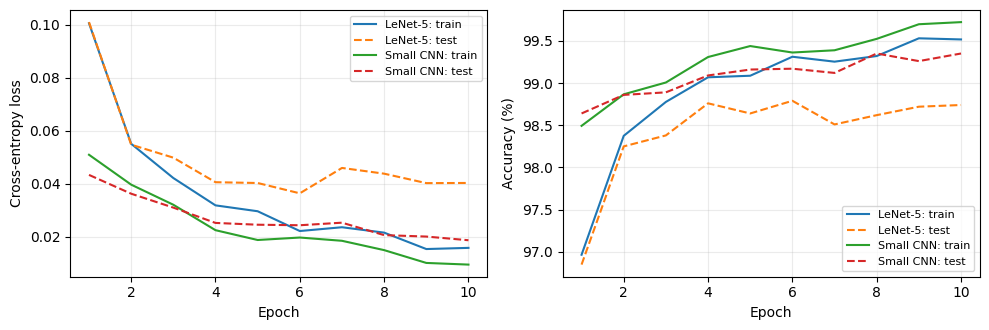

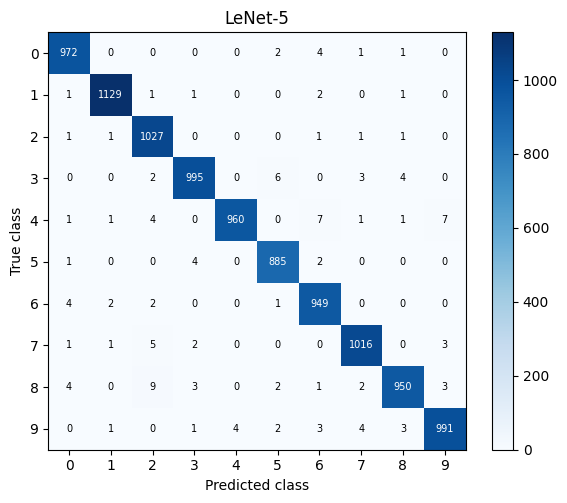

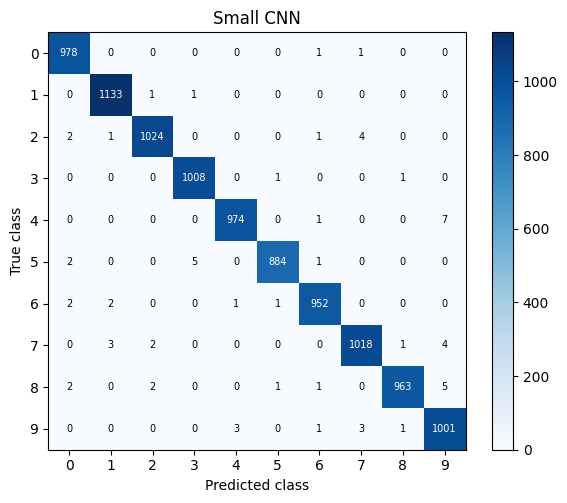

In [40]:
q2_models = {}
q2_histories = {}
q2_results = {}
q2_confusions = {}

for name, constructor in [
    ("LeNet-5", LeNet5),
    ("Small CNN", SmallCNN),
]:
    seed_everything()

    loaders = mnist_loaders()
    model = constructor().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=Q2_LR,
    )

    history, info = fit_model(
        model,
        loaders,
        epochs=Q2_EPOCHS,
        optimizer=optimizer,
        heldout="test",
        restore_best=False,
        name=name,
    )

    criterion = nn.CrossEntropyLoss()

    train_metrics = run_epoch(
        model, loaders["train_eval"], criterion
    )
    test_metrics = run_epoch(
        model, loaders["test"], criterion
    )

    metrics = {
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["acc"],
        "test_loss": test_metrics["loss"],
        "test_acc": test_metrics["acc"],
    }

    confusion = test_confusion(
        model, loaders["test"]
    )

    assert confusion.sum() == len(loaders["test"].dataset)

    q2_histories[name] = history
    q2_results[name] = metrics
    q2_confusions[name] = confusion

    # Store completed models and checkpoints on the CPU.
    model.cpu()
    q2_models[name] = model

    save_run(
        f"q2_{constructor.__name__}",
        history,
        {
            **metrics,
            **info,
            "epochs": Q2_EPOCHS,
            "batch_size": Q2_BATCH_SIZE,
            "lr": Q2_LR,
            "optimizer": "Adam",
            "epoch_metrics": "evaluation mode",
        },
        model.state_dict(),
    )

    np.save(
        RESULT_DIR / f"q2_{constructor.__name__}_confusion.npy",
        confusion,
    )

result_table(["LeNet-5", "Small CNN"], q2_results)
plot_histories(q2_histories)

for name, matrix in q2_confusions.items():
    plot_confusion(
        matrix,
        name,
        class_names=list(range(10)),
    )

### Results and discussion

After 10 epochs, LeNet-5 achieved **99.52% training accuracy** and **98.74% test accuracy**. Small CNN achieved **99.72% training accuracy** and **99.35% test accuracy**. Its test cross-entropy loss was also lower: **0.0187**, compared with **0.0403** for LeNet-5.

Both models learned rapidly during the first few epochs. LeNet-5’s test loss fluctuated after epoch 4 while its training loss generally decreased, suggesting mild overfitting. Small CNN maintained a smaller final training–test accuracy gap: **0.37 percentage points**, compared with **0.78** for LeNet-5.

The confusion matrices are strongly concentrated along the diagonal. LeNet-5 misclassified 126 test images, while Small CNN misclassified 65. For example, the number of digit 8 images incorrectly predicted as digit 2 decreased from **9 to 2**.

Small CNN performed better under the shared training settings. Its wider convolutional layers, ReLU activations, batch normalisation and dropout may contribute to this result. However, this comparison changes several architectural features together, so it cannot identify the contribution of each feature separately.